## State-based optimisation for SQEs

In [1]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.sqe_state import sqe_optimisation
from pulse_vqe_entanglement.plotting_state import plot_sqe_optimisation

### Strong initiallisation

Tracing control amplitude graph.
Infidelity: I=3.307e-15, nit=5, success=True, grad_norm=2.879e-08, S=3.521e-01
[outer 00] I=7.861e-09, lam=7.960494e+01, inner_nit=34, inner_success=True, constraint_residual=7.860e-09, S=1.752e-07
[outer 01] I=1.541e-12, lam=7.961034e+01, inner_nit=2, inner_success=True, constraint_residual=5.405e-13, S=1.920e-07
[outer 02] I=1.542e-12, lam=7.961577e+01, inner_nit=1, inner_success=True, constraint_residual=5.424e-13, S=1.920e-07
[outer 03] I=1.544e-12, lam=7.962120e+01, inner_nit=1, inner_success=True, constraint_residual=5.435e-13, S=1.920e-07
[outer 04] I=1.487e-12, lam=7.962607e+01, inner_nit=1, inner_success=True, constraint_residual=4.866e-13, S=1.920e-07


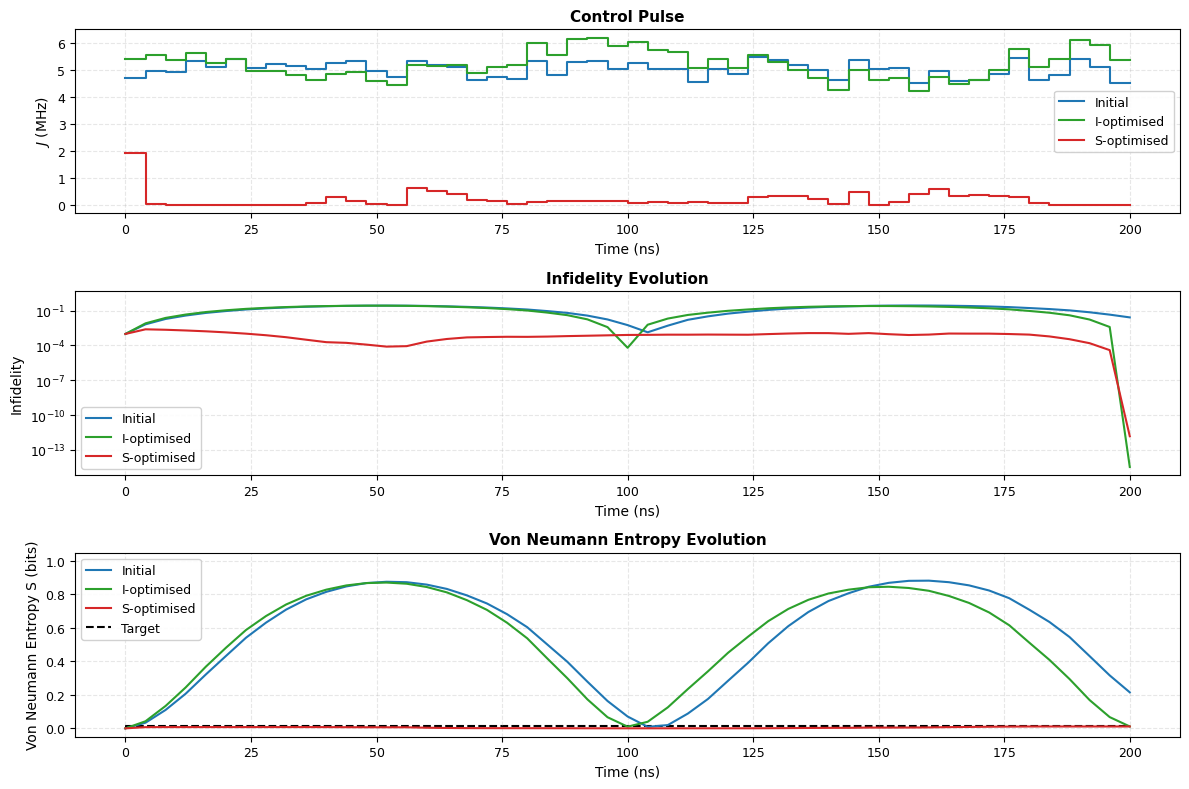

In [6]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128),
    theta_target=0.01 * np.pi,
    n_time_steps=50,
    n_discretisation=1,
    T=200.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-1,
    J_init_mean=-0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e10,
    n_outer=5,
    inner_maxiter=200,
    fd_eps=1e-6,
)

results = sqe_optimisation(config)
plot_sqe_optimisation(results)

### Weak initialisation

Tracing control amplitude graph.
Infidelity: I=-2.204e-16, nit=4, success=True, grad_norm=8.978e-11, S=7.788e-08
[outer 00] I=2.473e-09, lam=2.571808e+01, inner_nit=4, inner_success=True, constraint_residual=2.472e-09, S=7.237e-08
[outer 01] I=6.768e-12, lam=2.577576e+01, inner_nit=2, inner_success=True, constraint_residual=5.768e-12, S=7.720e-08
[outer 02] I=4.721e-12, lam=2.581297e+01, inner_nit=1, inner_success=True, constraint_residual=3.721e-12, S=7.720e-08
[outer 03] I=3.258e-12, lam=2.583556e+01, inner_nit=1, inner_success=True, constraint_residual=2.258e-12, S=7.723e-08
[outer 04] I=4.726e-12, lam=2.587281e+01, inner_nit=1, inner_success=True, constraint_residual=3.726e-12, S=7.719e-08


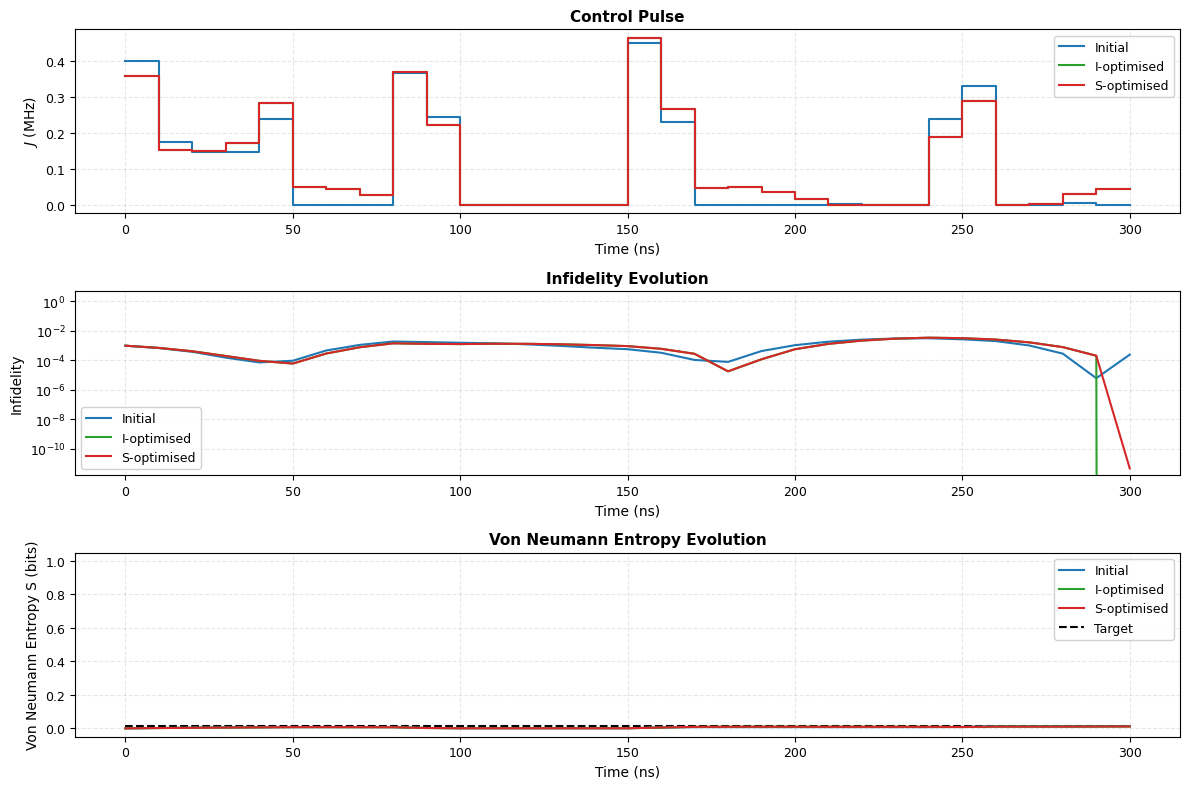

In [3]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128),
    theta_target=0.01 * np.pi,
    n_time_steps=30,
    n_discretisation=1,
    T=300.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-1,
    J_init_mean=-1.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e10,
    n_outer=5,
    inner_maxiter=500,
    fd_eps=1e-6,
)

results = sqe_optimisation(config)
plot_sqe_optimisation(results)